---
title: "Do the top private schools lose their students?"
description: The private colleges that dominate the top of the school ranking are often suspected of shedding weaker students on the way up. The ministry's own retention data says the opposite: the private sector retains almost everyone it enrols, and the gap is widest exactly where the ranking is highest.
categories:
- Methods & Inference
date: '2026-10-31'
draft: true
cap-location: margin
format:
  html:
    code-fold: true
jupyter:
  kernelspec:
    display_name: Python 3 (main)
    language: python
    name: main
---

Every year the school ranking puts a wall of private colleges at the top, and every year the same suspicion is voiced about them. These are schools that select by interview, by fees, and by prior marks; the story goes that they keep the students who were going to do well anyway and let the rest drain away before the exams. The suspicion is specific enough to test. If dropout were a large part of the private advantage, the private sector should lose a large share of its students between enrolment and the end of secondary school. The ministry publishes a statistic that measures almost exactly this, for every school with upper-secondary courses, and the answer runs the other way: the private sector retains nearly everyone, and the top of the ranking is where retention is closest to total.

## 1. The hypothesis and the data

The hypothesis, stated so it can fail: private schools, and in particular the high-ranking ones, have a higher rate of students leaving before the end of the course than public schools.

Three sources go into the test. The first is the ministry's InfoEscolas portal, which publishes per-school files with the *taxa de retenção ou desistência*, the share of enrolled students in a grade who either repeat the year or leave, for school years 2020/21 to 2023/24. The second is the same portal's *conclusão no tempo esperado*, the share of a school's students who finish the course on time, which is the complement of the story in a cleaner form. The third is the 2026 Correio da Manhã table, the republication of the national exam results, which supplies the ranking and the public/private label through the school-level join described in the data note. The retention and completion figures refer to school year 2023/24; the ranking is the most recent edition. Nothing in the test requires the two to be contemporaneous, because the question is about stable school characteristics, not about a single cohort.

In [1]:
from pathlib import Path
import csv
import random
import statistics as st

import numpy as np
import matplotlib.pyplot as plt

# Validated categorical palette (dataviz reference instance, slots 1-3).
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 120, "font.size": 9, "axes.titlesize": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "figure.facecolor": "white",
})

# Data lives in a private repository next to the site checkout (see data note).
CANDIDATES = [
    Path("../projects/school_rankings_pt/data"),
    Path("../../projects/school_rankings_pt/data"),
    Path("projects/school_rankings_pt/data"),
]
DATA = next(p for p in CANDIDATES if p.exists())

def load(name):
    with open(DATA / name, encoding="utf-8") as f:
        return list(csv.DictReader(f))

natureza = {r["code"]: r["natureza"] for r in load("infoescolas_natureza.csv")}

# Retention-or-dropout per school: mean of the 2023/24 rates for years 10 and 11
# (the latest year in the file); schools missing those grades fall back to 2022/23.
retencao = load("infoescolas_retencao_ch.csv")
by_school = {}
for r in retencao:
    by_school.setdefault(r["codigo"], {})[(r["ano"], r["ano_escolar"])] = float(r["taxa_retencao_ou_desistencia"])

ret = {}
for code, d in by_school.items():
    vals = [d[(y, g)] for y, g in [("2023/2024", "10.º Ano"), ("2023/2024", "11.º Ano")] if (y, g) in d]
    if not vals:
        vals = [d[(y, g)] for y, g in [("2022/2023", "10.º Ano"), ("2022/2023", "11.º Ano"),
                                       ("2022/2023", "12.º Ano")] if (y, g) in d]
    if vals:
        ret[code] = st.mean(vals)

recs = [(c, v, natureza[c]) for c, v in ret.items() if c in natureza]
n_pub = sum(1 for _, _, n in recs if n == "Publico")
n_pri = len(recs) - n_pub
print(f"{len(recs)} schools with retention data and a public/private label "
      f"({n_pub} public, {n_pri} private)")

584 schools with retention data and a public/private label (485 public, 99 private)


## 2. The measure, and what it conflates

The published rate is a combined one: a student counts against the school either for repeating the year (*retenção*) or for leaving it (*desistência*). Pure dropout, in the sense of abandoning the school system, is only one of the two components, and the file does not separate them. This is a real limitation, but it cuts in a known direction. A sector with heavy grade repetition would look bad on this measure even with zero abandonment, so the combined rate is, if anything, a conservative instrument for the hypothesis: it gives the private sector every chance to look worse by loading repetition onto the same number.

Two properties of the data are worth stating before the comparison. The rates are school-level, computed from enrollment records, so a student who transfers to another school sits in a definitional grey zone that I return to in Section 6. And the denominators are the students enrolled in each grade, so the measure is a flow within the school year, not a graduation rate; the completion measure below covers the other side.

retention-or-dropout, school year 2023/24, mean of years 10-11:
  public  n=485: median 7.5  IQR [4.5, 11.5]  mean 8.8
  private n= 99: median 0.5  IQR [0.0, 3.0]  mean 1.9
  median difference (private - public): -7.0 pp, permutation p = 0.0002


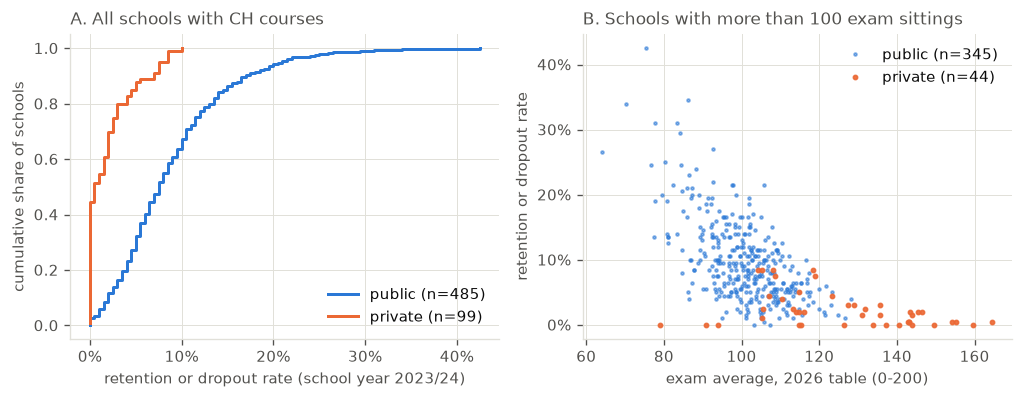

In [2]:
def perm_p(a, b, n=5000, seed=42):
    """Permutation p-value for the difference in medians (label shuffle)."""
    obs = st.median(a) - st.median(b)
    pool = a + b
    na = len(a)
    rng = random.Random(seed)
    cnt = 0
    for _ in range(n):
        rng.shuffle(pool)
        if abs(st.median(pool[:na]) - st.median(pool[na:])) >= abs(obs):
            cnt += 1
    return obs, (cnt + 1) / (n + 1)

def spread(vals, pct=True, dec=None):
    vals = sorted(vals)
    m = 100 if pct else 1
    d = dec if dec is not None else (1 if pct else 3)
    n = len(vals)
    return (f"median {st.median(vals)*m:.{d}f}  IQR [{vals[n//4]*m:.{d}f}, {vals[3*n//4]*m:.{d}f}]  "
            f"mean {st.mean(vals)*m:.{d}f}")

pub = [v for _, v, n in recs if n == "Publico"]
pri = [v for _, v, n in recs if n == "Privado"]
obs, p = perm_p(pri, pub)
print("retention-or-dropout, school year 2023/24, mean of years 10-11:")
print(f"  public  n={len(pub):3d}: {spread(pub)}")
print(f"  private n={len(pri):3d}: {spread(pri)}")
print(f"  median difference (private - public): {obs*100:+.1f} pp, permutation p = {p:.4f}")

# Figure 1: ECDF by sector, and retention against exam average inside the ranking.
cmap = {}
for r in load("cm2026_natureza_map.csv"):
    if r["ie_code"] and r["natureza"] in ("Publico", "Privado"):
        code = r["ie_code"]
        if code not in cmap or int(r["n"]) > int(cmap[code]["n"]):
            cmap[code] = r

hi = [(float(r["media"]), int(r["n"]), c, r["natureza"]) for c, r in cmap.items() if int(r["n"]) > 100]
hi.sort(key=lambda x: -x[0])
rank_of = {c: i + 1 for i, (_, _, c, _) in enumerate(hi)}

fig, (axA, axB) = plt.subplots(1, 2, figsize=(8.6, 3.4))

def ecdf(ax, vals, color, label):
    xs = np.sort(vals)
    ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", color=color, lw=1.8, label=label)

ecdf(axA, pub, BLUE, f"public (n={len(pub)})")
ecdf(axA, pri, ORANGE, f"private (n={len(pri)})")
axA.set_xlabel("retention or dropout rate (school year 2023/24)")
axA.set_ylabel("cumulative share of schools")
axA.xaxis.set_major_formatter(lambda x, _: f"{x*100:.0f}%")
axA.legend(loc="lower right")
axA.set_title("A. All schools with CH courses", loc="left", color=INK2)

pts_pub = [(m, ret[c]) for m, n, c, nt in hi if nt == "Publico" and c in ret]
pts_pri = [(m, ret[c]) for m, n, c, nt in hi if nt == "Privado" and c in ret]
axB.plot([m for m, _ in pts_pub], [v for _, v in pts_pub], ".", color=BLUE, ms=3.5, alpha=0.55,
         label=f"public (n={len(pts_pub)})")
axB.plot([m for m, _ in pts_pri], [v for _, v in pts_pri], ".", color=ORANGE, ms=5, alpha=0.9,
         label=f"private (n={len(pts_pri)})")
axB.yaxis.set_major_formatter(lambda y, _: f"{y*100:.0f}%")
axB.set_xlabel("exam average, 2026 table (0-200)")
axB.set_ylabel("retention or dropout rate")
axB.legend(loc="upper right")
axB.set_title("B. Schools with more than 100 exam sittings", loc="left", color=INK2)

fig.tight_layout()
plt.show()

## 3. Public against private

The distributions barely overlap. Across the 584 mainland schools that have both the retention data and a public/private label, the median public school loses or holds back 7.5% of an enrolled grade in a year; the median private school, 0.5%. The interquartile ranges run from 4.5% to 11.5% against 0% to 3.0%. A label-shuffle test on the difference in medians gives a p-value below 0.001, which is no surprise at this sample size; the interesting content is not the significance but the shape. Three quarters of the private schools sit at or below 3%, a level that fewer than a quarter of public schools reach.

The completion measure tells the same story from the other end. The share of students finishing the course on time (*conclusão no tempo esperado*, 2023/24) has a public median of 76.9% against a private median of 91.1%. A sector cannot show both a low combined retention-or-dropout rate and a high on-time completion rate by gaming either number; the two are reported in the same files and are computed on different quantities, and they agree.

In [3]:
cte_rows = [r for r in load("infoescolas_cte_ch.csv")
            if r["ano"] == "2023/2024" and "escola que" in r["medida"]]
school_cte = {r["codigo"]: float(r["valor"]) for r in cte_rows}
recs2 = [(c, v, natureza[c]) for c, v in school_cte.items() if c in natureza]
pub2 = [v for _, v, n in recs2 if n == "Publico"]
pri2 = [v for _, v, n in recs2 if n == "Privado"]
obs2, p2 = perm_p(pri2, pub2)
print(f"completion on time, 2023/24: public n={len(pub2)} {spread(pub2)}")
print(f"                             private n={len(pri2)} {spread(pri2)}")
print(f"median difference (private - public): {obs2*100:+.1f} pp, permutation p = {p2:.4f}")

pub_hi = [(m, ret[c]) for m, n, c, nt in hi if nt == "Publico" and c in ret]
pri_hi = [(m, ret[c]) for m, n, c, nt in hi if nt == "Privado" and c in ret]
obs3, p3 = perm_p([v for _, v in pri_hi], [v for _, v in pub_hi])
print()
print(f"ranking set (more than 100 exam sittings, {len(hi)} schools):")
print(f"  public  n={len(pub_hi):3d}: {spread([v for _, v in pub_hi])}")
print(f"  private n={len(pri_hi):3d}: {spread([v for _, v in pri_hi])}")
print(f"  median difference (private - public): {obs3*100:+.1f} pp, permutation p = {p3:.4f}")

k = len(hi) // 4
top_codes = {c for _, _, c, _ in hi[:k]}
top = [(m, ret[c], nt) for m, n, c, nt in hi if c in top_codes and c in ret]
tp = [v for _, v, nt in top if nt == "Publico"]
tr = [v for _, v, nt in top if nt == "Privado"]
obs4, p4 = perm_p(tr, tp)
print()
print(f"top quartile of the ranking (top {k} by exam average):")
print(f"  public  n={len(tp):3d}: {spread(tp)}")
print(f"  private n={len(tr):3d}: {spread(tr)}")
print(f"  median difference (private - public): {obs4*100:+.1f} pp, permutation p = {p4:.4f}")

def spearman(xs, ys):
    def rank(v):
        order = sorted(range(len(v)), key=lambda i: v[i])
        r = [0.0] * len(v)
        i = 0
        while i < len(order):
            j = i
            while j + 1 < len(order) and v[order[j + 1]] == v[order[i]]:
                j += 1
            for t in range(i, j + 1):
                r[order[t]] = (i + j) / 2
            i = j + 1
        return r
    rx, ry = rank(xs), rank(ys)
    mx, my = st.mean(rx), st.mean(ry)
    num = sum((a - mx) * (b - my) for a, b in zip(rx, ry))
    den = (sum((a - mx) ** 2 for a in rx) * sum((b - my) ** 2 for b in ry)) ** 0.5
    return num / den

allm = [m for m, _ in pub_hi] + [m for m, _ in pri_hi]
allv = [v for _, v in pub_hi] + [v for _, v in pri_hi]
print()
print(f"rank correlation between exam average and retention, ranking set: {spearman(allm, allv):+.2f}")
print(f"  public only:  {spearman([m for m, _ in pub_hi], [v for _, v in pub_hi]):+.2f}")
print(f"  private only: {spearman([m for m, _ in pri_hi], [v for _, v in pri_hi]):+.2f}")

completion on time, 2023/24: public n=476 median 76.9  IQR [74.9, 78.5]  mean 76.4
                             private n=87 median 91.1  IQR [87.7, 92.1]  mean 88.4
median difference (private - public): +14.3 pp, permutation p = 0.0002



ranking set (more than 100 exam sittings, 392 schools):
  public  n=345: median 8.5  IQR [5.0, 13.0]  mean 9.8
  private n= 44: median 1.8  IQR [0.0, 3.0]  mean 2.4
  median difference (private - public): -6.8 pp, permutation p = 0.0002



top quartile of the ranking (top 98 by exam average):
  public  n= 62: median 5.0  IQR [3.0, 6.5]  mean 5.3
  private n= 34: median 1.5  IQR [0.0, 2.5]  mean 1.9
  median difference (private - public): -3.5 pp, permutation p = 0.0002

rank correlation between exam average and retention, ranking set: -0.61
  public only:  -0.56
  private only: -0.34


## 4. Inside the ranking

Restricting to the 392 schools with more than 100 exam sittings that carry a public/private label, the gap narrows but does not close: public median 8.5% against private 1.8%. In the top quartile of the ranking the medians are 5.0% and 1.5%, and the twenty highest-ranked private schools all sit at or under 3%. Panel B of the figure shows the pattern directly: the orange points (private) crowd the bottom of the retention axis at every level of exam average, while the blue points spread upward, and the highest retention values in the top quartile all belong to public schools.

The correlation between exam average and retention is negative everywhere, at -0.61 over the whole ranking set, -0.56 within the public sector and -0.34 within the private one. Better exam results go with less retention and dropout in both sectors; the private advantage is not an artifact of pooling two differently-shaped distributions, though it is stronger across sectors than within them.

cohort survival, year 10 (2020/21) to year 12 (2022/23):
  public  n=480: median 0.861  IQR [0.798, 0.920]  mean 0.855
  private n= 94: median 0.946  IQR [0.869, 1.039]  mean 0.962
  median difference (private - public): +0.085, permutation p = 0.0002



exam sitters (2024 edition) per year-12 student (2022/23):
  public  n=420: median 4.033  IQR [3.585, 4.511]  mean 4.111
  private n= 71: median 4.212  IQR [3.723, 4.870]  mean 4.728
  median difference (private - public): +0.180, permutation p = 0.1388


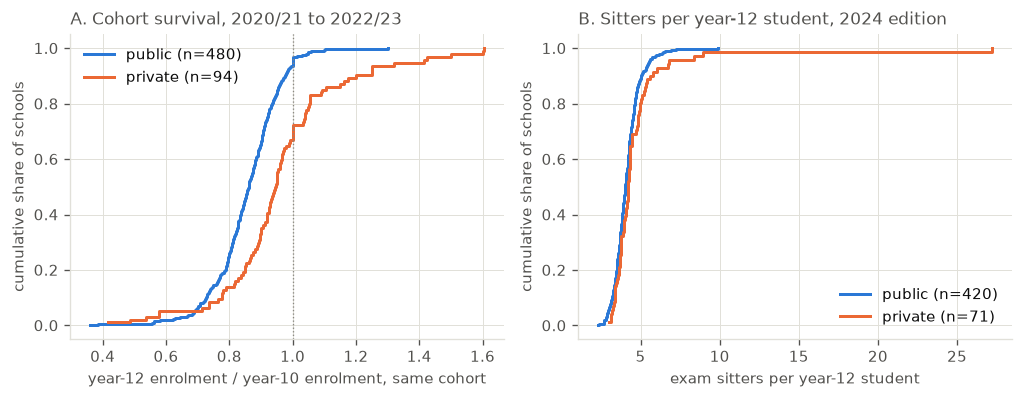

In [4]:
# Corroboration A: cohort survival from enrolment alone (no exam data involved).
# Year-10 enrolment in 2020/21 against year-12 enrolment in 2022/23, same cohort.
pop = load("infoescolas_populacao_ch.csv")
enr = {}
for r in pop:
    enr.setdefault(r["codigo"], {})[(r["ano"], r["ano_escolar"])] = int(r["alunos"])

sur_pub, sur_pri = [], []
for c, d in enr.items():
    if c not in natureza:
        continue
    e10 = d.get(("2020/2021", "10.º Ano"))
    e12 = d.get(("2022/2023", "12.º Ano"))
    if not e10 or e10 < 10 or e12 is None:
        continue
    (sur_pub if natureza[c] == "Publico" else sur_pri).append(e12 / e10)

obs5, p5 = perm_p(sur_pri, sur_pub)
print(f"cohort survival, year 10 (2020/21) to year 12 (2022/23):")
print(f"  public  n={len(sur_pub):3d}: {spread(sur_pub, pct=False)}")
print(f"  private n={len(sur_pri):3d}: {spread(sur_pri, pct=False)}")
print(f"  median difference (private - public): {obs5:+.3f}, permutation p = {p5:.4f}")

# Corroboration B: exam sitters per year-12 student, cohort-consistent.
# CM edition 2024 covers the exams sat in June 2023, the end of school year
# 2022/23 for the 2022/23 year-12 cohort.
comb = load("../cm_school_rankings_editions_2020_2026.csv")
sitters = {(r["edition"], r["escola"]): int(r["n_alunos_exame"]) for r in comb
           if r["table"] == "secundario-geral" and r["n_alunos_exame"]}
cmap24 = {}
for r in load("cm2024_natureza_map.csv"):
    if r["ie_code"] and r["natureza"] in ("Publico", "Privado"):
        code = r["ie_code"]
        if code not in cmap24 or int(r["n"]) > int(cmap24[code]["n"]):
            cmap24[code] = r

hi24 = [(float(r["media"]), r["escola"], c, r["natureza"]) for c, r in cmap24.items() if int(r["n"]) > 100]
sr_pub, sr_pri = [], []
for media, escola, c, nt in hi24:
    e12 = enr.get(c, {}).get(("2022/2023", "12.º Ano"))
    n_sit = sitters.get(("2024", escola))
    if e12 and n_sit:
        (sr_pub if nt == "Publico" else sr_pri).append(n_sit / e12)

obs6, p6 = perm_p(sr_pri, sr_pub)
print()
print(f"exam sitters (2024 edition) per year-12 student (2022/23):")
print(f"  public  n={len(sr_pub):3d}: {spread(sr_pub, pct=False)}")
print(f"  private n={len(sr_pri):3d}: {spread(sr_pri, pct=False)}")
print(f"  median difference (private - public): {obs6:+.3f}, permutation p = {p6:.4f}")

fig, (axA, axB) = plt.subplots(1, 2, figsize=(8.6, 3.4))
ecdf(axA, sur_pub, BLUE, f"public (n={len(sur_pub)})")
ecdf(axA, sur_pri, ORANGE, f"private (n={len(sur_pri)})")
axA.axvline(1.0, color=MUTED, lw=0.8, ls=":")
axA.set_xlabel("year-12 enrolment / year-10 enrolment, same cohort")
axA.set_ylabel("cumulative share of schools")
axA.legend(loc="upper left")
axA.set_title("A. Cohort survival, 2020/21 to 2022/23", loc="left", color=INK2)

ecdf(axB, sr_pub, BLUE, f"public (n={len(sr_pub)})")
ecdf(axB, sr_pri, ORANGE, f"private (n={len(sr_pri)})")
axB.set_xlabel("exam sitters per year-12 student")
axB.set_ylabel("cumulative share of schools")
axB.legend(loc="lower right")
axB.set_title("B. Sitters per year-12 student, 2024 edition", loc="left", color=INK2)

fig.tight_layout()
plt.show()

## 5. Two corroborations

The first corroboration drops the exam data entirely. Taking the year-10 enrolment of 2020/21 and following the same cohort to year 12 in 2022/23, the public median school retains 0.861 of its cohort at year 12; the private median, 0.946. A ratio below one means the cohort shrank, through dropout or through slower progression; a ratio above one means repetition inflows outweighing attrition. The private distribution sits visibly to the right, and its upper tail above one is the signature of schools that hold repetition near zero.

The second corroboration goes back to the exam table, now as a denominator check. If private schools were losing students before the exams, fewer of their enrolled students would appear as exam sitters. Counting sitters in the 2024 edition, which covers the exams sat at the end of school year 2022/23, per student enrolled in year 12 that same year, the private median is 4.21 against a public median of 4.03 (permutation p = 0.14): the private sector sits, if anything, slightly above. The crude prediction of the dropout hypothesis fails in both tests.

## 6. What this cannot tell you

Three limits bound the conclusion. The first is the conflation already described: the headline rate mixes repetition with abandonment, and the files do not separate them. The completion measure partially covers this, since a sector cannot post a 91% on-time completion rate on the back of heavy repetition; but pure abandonment in the final years, after the retention-relevant grades, is only loosely bounded by these numbers.

The second is the transfer channel. The rates are computed from school enrollment records, and whether a student who moves to another school mid-course counts as a *desistência* at the original school is a definitional detail I could not settle from the published material. If transfers are counted, the result above is conservative, because the suspicion about private schools is precisely that they push weak students out, and the data would then already be loading that behaviour onto their numbers. If transfers are not counted, part of the private advantage could be weak students moving to the public system without penalty. The published files do not allow me to distinguish these cases, so I state the result as a property of the recorded rates, not of the underlying behaviour.

The third limit is the one that applies to every school-level comparison in this series: selection. Private schools choose their intake, publicly funded ones mostly do not. That the top private schools retain essentially everyone they enrol is a fact about the matched pair of student and school, not evidence that the school would produce the same retention with an unselected intake. The honest summary is that the dropout hypothesis fails on its own terms, and what remains is a selection story, which is a different claim and a harder one to test with published aggregates.

## Take-home

- The hypothesis that private schools, especially the high-ranking ones, lose more students is rejected on the ministry's own data. The median public school records a 7.5% retention-or-dropout rate against 0.5% for the median private school; in the top quartile of the ranking the medians are 5.0% and 1.5%.
- The complement confirms it: on-time completion is 91.1% in the private sector against 76.9% in the public one.
- Two independent corroborations agree: cohorts shrink far less in private schools between year 10 and year 12, and private schools do not sit fewer exams per enrolled student.
- What survives is selection, not dropout. The ranking's private top is not built on shedding weak students, as far as the recorded rates can see; it is built on who enrols in the first place. Both facts are consistent with the earlier result in this series, that rank differences overstate grade differences: the schools at the top are operating on a different intake, and position in the list is not evidence about what they add.

**Data and code note.** The retention-or-dropout and completion rates come from the InfoEscolas portal (infoescolas.medu.pt), per-school files for secondary education, 2025 edition (school year 2023/24), sheets *Retencao* and *ConclusãoTempoEsperado* of the cursos científico-humanísticos file; the portal covers mainland schools only, so Azorean and Madeiran schools, and a dozen private schools the list omits, are absent from the joins. The public/private label comes from the portal's school search filter, joined to the exam tables by normalized-name matching with concelho agreement (about 92% coverage on the filtered ranking set). The exam table is the 2026 Correio da Manhã ranking ([results/2026/1](https://www.cmjornal.pt/datajournalism/schoolresults/results/2026/1)), a republication of the Ministério da Educação / JNE results, restricted here to schools with more than 100 exam sittings; the 2024 edition plays the same role for the sitter ratio. All extracts and scripts live in a private data repository alongside the site checkout; the notebook reads them by relative path. Retention values for schools with fewer than 20 students in a grade are suppressed by the ministry and treated here as missing. The permutation tests shuffle sector labels 5,000 times and compare medians; they are robustness checks on differences whose size is visible in the raw distributions.